# Where Does Home Field Matter Most: NFL or College Football?

**Part 2 of the project.** Part 1 ([`analysis.ipynb`](analysis.ipynb), [`deep_dive.ipynb`](deep_dive.ipynb)) measured home field in the NFL. This notebook repeats it for college football (FBS) and compares the two leagues.

**The trap:** raw home win % is not a fair yardstick between leagues.
- In college, strong schools often schedule weaker visitors at home, which inflates home records.
- College has bigger talent gaps, so many games are decided before kickoff no matter where they're played.

So the comparison is done twice: first with raw win %, then with Part 1's rating model, which removes team strength and gives the home edge **in points between two equally good teams**.

Steps: pull from the CollegeFootballData.com API → clean → load into Postgres (`cfb` schema + `compare` view) → SQL → raw statistics → strength-adjusted statistics → charts.

## 1. Pull the data
Every regular-season college game 2015–2025 from `https://api.collegefootballdata.com/games` (one call per season). The free API key lives in `.env` as `CFBD_API_KEY` and is never printed. Column names are converted from camelCase to snake_case (`homeTeam` → `home_team`). The helper code is in [`cfb.py`](cfb.py).

The raw pull is saved to `data/`, so re-running the notebook doesn't call the API again.

In [1]:
import os
import math
from statistics import NormalDist
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf
from scipy.stats import chi2
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
import cfb
import hfa

os.makedirs("data", exist_ok=True)
RAW = "data/raw_cfb_games.csv"
if os.path.exists(RAW):
    raw = pd.read_csv(RAW, low_memory=False)
else:
    raw = cfb.pull_games(2015, 2025)
    raw.to_csv(RAW, index=False)
print(raw.shape)
raw.groupby("home_classification").size()   # FBS, FCS, Division II and III are all in the pull

(25301, 34)


home_classification
fbs    9061
fcs    6939
ii     4403
iii    4826
dtype: int64

## 2. Clean the data
| Rule | Why |
| --- | --- |
| Both teams FBS | Top division vs. top division (no FCS or lower-division visitors) |
| Drop neutral sites | Nobody is really "home" (kickoff classics, rivalry games at NFL stadiums) |
| Completed games only | Some 2020 games were cancelled |
| Drop ties | Not a win or a loss (rare since overtime came in) |
| Drop conference title games | The higher seed hosts: the college version of the playoffs, which Part 1 also excluded. The API only labels them from 2022, so earlier ones are found by date (see `cfb.title_game_ids`) |
| Keep only the home team's usual stadium | Same rule as Part 1: drops hurricane moves, second "home" stadiums and mislabelled rows (and, because some venue labels in the API are inconsistent, a few genuine home games) |

Same new columns as the NFL table (`home_win`, `margin`, `covid_season`) plus `conference_game` (1 = both teams in the same conference). The NFL table needs no stadium filter: for 2015–2025, every NFL game marked "Home" was at the home team's usual stadium.

In [2]:
games = cfb.clean(raw)
print(f"{len(games):,} games, {games.home_team.nunique()} teams, {games.conference_game.sum():,} conference games")
games.groupby("season").agg(games=("game_id", "size"), conference=("conference_game", "sum")).T

7,586 games, 137 teams, 5,580 conference games


season,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
games,697,688,712,702,709,495,700,711,724,713,735
conference,503,507,518,509,510,437,504,512,531,512,537


## 3. Load into the database
College games go in their own `cfb` schema; the comparison view lives in a `compare` schema. `nfl.games` and the dashboard's other tables are not touched. The view is dropped first because it depends on `cfb.games`, then rebuilt from [`sql/05_create_league_view.sql`](sql/05_create_league_view.sql).

In [3]:
load_dotenv()
engine = create_engine(os.environ["DB_URL"])
with engine.begin() as conn:
    conn.execute(text("CREATE SCHEMA IF NOT EXISTS cfb"))
    conn.execute(text("DROP VIEW IF EXISTS compare.league_games"))
games.to_sql("games", engine, schema="cfb", if_exists="replace", index=False)
with engine.begin() as conn:
    conn.execute(text(open("sql/05_create_league_view.sql").read()))
pd.read_sql("SELECT league, COUNT(*) AS games FROM compare.league_games GROUP BY league ORDER BY league", engine)

,league,games
0,College (all FBS),7586
1,College (conference),5580
2,NFL,2837


## 4. First look with SQL (raw win %)

In [4]:
def run(file):
    with open(f"sql/{file}") as f:
        return pd.read_sql(f.read(), engine)

compare = run("06_league_compare.sql")
by_season = run("07_league_by_season.sql")
fans = run("08_league_fan_effect.sql")
crowds = run("09_cfb_2020_crowds.sql")
compare

,league,games,home_win_pct,edge_over_50,avg_home_margin
0,College (all FBS),7586,58.6,8.6,4.3
1,College (conference),5580,55.6,5.6,2.4
2,NFL,2837,54.6,4.6,1.8


In [5]:
by_season.pivot(index="season", columns="league", values="home_win_pct")

league,College (all FBS),College (conference),NFL
season,,,
2015,56.5,53.3,53.8
2016,58.4,55.6,57.8
2017,57.9,54.2,57.0
2018,59.8,56.0,60.6
2019,60.1,57.8,52.0
2020,56.8,55.8,50.4
2021,58.1,55.6,51.1
2022,58.5,54.5,56.7
2023,58.4,56.7,55.8


In [6]:
fans

,league,normal_games,games_2020,normal_home_win_pct,home_win_pct_2020,drop_in_2020,pct_of_edge_lost
0,NFL,2585.0,252.0,55.0,50.4,4.7,92.0
1,College (conference),5143.0,437.0,55.6,55.8,-0.3,-5.0
2,College (all FBS),7091.0,495.0,58.7,56.8,1.9,22.0


Raw numbers say college home teams win a lot more (58.6% across all FBS games), and that 2020 hurt the NFL but not college conference games. **Both of those readings are misleading** once team strength is removed (section 6): the first is mostly scheduling, and the second hides a drop of similar size in college.

## 5. Raw win %: is it more than luck?
- **95% range** for each group's home win % (`proportion_confint`, Wilson method).
- **p-values** (`proportions_ztest`). Below 0.05 = unlikely to be luck.

In [7]:
rows = pd.read_sql("SELECT league, covid_season, home_win FROM compare.league_games", engine)

def ci(g):
    lo, hi = proportion_confint(g.sum(), len(g), method="wilson")
    return pd.Series({"games": len(g), "home_win_pct": 100 * g.mean(), "low_95": 100 * lo, "high_95": 100 * hi})

rows.groupby("league").home_win.apply(ci).unstack().round(1)

,games,home_win_pct,low_95,high_95
league,,,,
College (all FBS),7586.0,58.6,57.4,59.7
College (conference),5580.0,55.6,54.3,56.9
NFL,2837.0,54.6,52.8,56.5


In [8]:
def p_value(a, b):
    return proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])[1]

league = {name: g for name, g in rows.groupby("league")}
tests = [("NFL vs. college conference", p_value(league["NFL"].home_win, league["College (conference)"].home_win))]
for name, g in league.items():
    tests.append((f"{name}: normal vs. 2020", p_value(g[g.covid_season == 0].home_win, g[g.covid_season == 1].home_win)))
pd.DataFrame(tests, columns=["test", "p_value"]).round(3)

,test,p_value
0,NFL vs. college conference,0.404
1,College (all FBS): normal vs. 2020,0.404
2,College (conference): normal vs. 2020,0.915
3,NFL: normal vs. 2020,0.157


## 6. Remove team strength
Part 1's rating model ([`hfa.py`](hfa.py)), fit separately each season: `home margin = home edge + rating[home] − rating[away]`. For every game, `adj_edge` = home margin minus the strength gap. Its average is the home edge in points between two equally good teams.

College ratings are fit on all FBS games, so conference games borrow strength information from non-conference games.

**Why raw win % misleads, in one table:** the average strength gap (home minus away, in points). In non-conference games the home team is usually the stronger school; in conference games home and away teams are balanced.

In [9]:
nfl = cfb.add_strength_adjusted_edge(pd.read_sql("SELECT * FROM nfl.games", engine))
col = cfb.add_strength_adjusted_edge(pd.read_sql("SELECT * FROM cfb.games", engine))
groups = {
    "NFL": nfl,
    "College (conference)": col[col.conference_game == 1],
    "College (non-conference)": col[col.conference_game == 0],
    "College (all FBS)": col,
}
pd.DataFrame({name: {"games": len(d),
                     "home_win_pct": round(100 * d.home_win.mean(), 1),
                     "avg_strength_gap_pts": round(d.strength_gap.mean(), 1),
                     "avg_size_of_gap_pts": round(d.strength_gap.abs().mean(), 1)}
              for name, d in groups.items()}).T

,games,home_win_pct,avg_strength_gap_pts,avg_size_of_gap_pts
NFL,2837.0,54.6,0.0,6.7
College (conference),5580.0,55.6,0.1,12.2
College (non-conference),2006.0,66.8,7.3,16.6
College (all FBS),7586.0,58.6,2.0,13.4


Non-conference home teams start about 7 points stronger, which is what pushes the all-FBS win % up. Conference games are **not** evenly matched (the typical gap is still large), but they are balanced between home and away, which is what matters here.

Next: the home edge in points for each group, normal seasons vs. 2020, straight from the rating model ([`cfb.season_home_edges`](cfb.py)). Each season gets its own estimate with a proper standard error (one that accounts for team ratings being estimated too, which matters in 2020 when teams played few games). Normal seasons are then pooled, giving more weight to more precise seasons, the same way Part 1 did. College conference and non-conference games each get their own home edge, while every game informs the team ratings. (In 2020 the college schedule split into four groups of teams that never played each other; the model handles that, because the home edge is still measured within each group.)

`equal_team_win_pct` turns points into "how often the home team would win if both teams were equally good" (using how much game results vary around the model). That's a fair win % to compare between leagues.

In [10]:
season_edges = pd.concat([
    cfb.season_home_edges(nfl).assign(group="NFL"),
    cfb.season_home_edges(col, "conference_game", {1: "College (conference)", 0: "College (non-conference)"}),
    cfb.season_home_edges(col).assign(group="College (all FBS)"),
], ignore_index=True)

def summary(e):
    p = cfb.pool(e)
    return pd.Series({"games": int(p.games), "home_edge_pts": p.home_edge, "se": p.se,
                      "low_95": p.home_edge - 1.96 * p.se, "high_95": p.home_edge + 1.96 * p.se,
                      "equal_team_win_pct": 100 * NormalDist().cdf(p.home_edge / p.sigma)})

order = ["NFL", "College (conference)", "College (non-conference)", "College (all FBS)"]
adj = pd.DataFrame([{"group": g, "period": per, **summary(e[(e.season == 2020) == (per == "2020")])}
                    for g, e in season_edges.groupby("group") for per in ["normal", "2020"]])
adj["group"] = pd.Categorical(adj.group, order); adj = adj.sort_values(["group", "period"], ascending=[True, False])
adj.round(2)

,group,period,games,home_edge_pts,se,low_95,high_95,equal_team_win_pct
6,NFL,normal,2585.0,1.89,0.24,1.41,2.36,56.15
7,NFL,2020,252.0,0.13,0.78,-1.40,1.65,50.42
2,College (conference),normal,5143.0,2.38,0.20,1.99,2.78,56.64
3,College (conference),2020,437.0,0.97,0.71,-0.41,2.36,52.70
4,College (non-conference),normal,1948.0,2.39,0.38,1.65,3.13,56.66
5,College (non-conference),2020,58.0,-2.00,2.51,-6.93,2.93,44.44
0,College (all FBS),normal,7091.0,2.38,0.18,2.04,2.73,56.64
1,College (all FBS),2020,495.0,0.76,0.68,-0.58,2.10,52.11


In [11]:
A = adj.set_index(["group", "period"])

def diff_test(a, b):
    """Difference of two estimates and its two-sided p-value (z-test on independent estimates)."""
    d, se = a.home_edge_pts - b.home_edge_pts, math.hypot(a.se, b.se)
    return d, se, hfa.norm_p(d / se)

nfl_drop = diff_test(A.loc[("NFL", "normal")], A.loc[("NFL", "2020")])
conf_drop = diff_test(A.loc[("College (conference)", "normal")], A.loc[("College (conference)", "2020")])
did = nfl_drop[0] - conf_drop[0], math.hypot(nfl_drop[1], conf_drop[1])
adj_tests = pd.DataFrame([
    ("Normal seasons: college conference minus NFL", *diff_test(A.loc[("College (conference)", "normal")], A.loc[("NFL", "normal")])),
    ("NFL: normal minus 2020", *nfl_drop),
    ("College conference: normal minus 2020", *conf_drop),
    ("College all FBS: normal minus 2020", *diff_test(A.loc[("College (all FBS)", "normal")], A.loc[("College (all FBS)", "2020")])),
    ("Did the NFL lose more than college? (NFL drop minus college drop)", did[0], did[1], hfa.norm_p(did[0] / did[1])),
], columns=["test", "difference_pts", "se", "p_value"])
adj_tests.round(3)

,test,difference_pts,se,p_value
0,Normal seasons: college conference minus NFL,0.496,0.314,0.114
1,NFL: normal minus 2020,1.759,0.814,0.031
2,College conference: normal minus 2020,1.412,0.735,0.055
3,College all FBS: normal minus 2020,1.626,0.705,0.021
4,Did the NFL lose more than college? (NFL drop ...,0.347,1.097,0.752


## 7. College 2020: did crowd size matter?
College attendance in 2020 ran from zero to about 27,000 (normal seasons: median about 36,000), so it allows a direct check. Raw numbers come from [`sql/09_cfb_2020_crowds.sql`](sql/09_cfb_2020_crowds.sql); the strength-adjusted edge per game and a straight-line trend come from pandas and statsmodels. (These ranges treat 2020 team ratings as known, so they are a bit too narrow.)

Two cautions: crowd size in 2020 mostly reflects **conference policy** (SEC, Big 12 and ACC schools allowed fans; the Big Ten, Pac-12, MAC and Mountain West mostly didn't), so the trend is also checked within conferences. And an attendance of 0 can sometimes mean "not recorded" rather than an empty stadium.

In [12]:
crowds

,crowd,games,home_win_pct,avg_home_margin
0,"1) 1,000 or fewer",180,53.3,0.7
1,"2) 1,001 to 10,000",153,56.2,0.9
2,"3) more than 10,000",144,63.2,6.0


In [13]:
c20 = col[(col.season == 2020) & col.attendance.notna()].copy()
c20["crowd"] = pd.cut(c20.attendance, [-1, 1000, 10000, 1e6], labels=["1,000 or fewer", "1,001 to 10,000", "more than 10,000"])
by_crowd = c20.groupby("crowd", observed=True).adj_edge.apply(lambda s: pd.Series(hfa.mean_ci(s)[:3], index=["home_edge_pts", "low_95", "high_95"])).unstack()
c20["fans_10k"] = c20.attendance / 10000
trend = smf.ols("adj_edge ~ fans_10k", c20).fit()
print(f"Each extra 10,000 fans: {trend.params['fans_10k']:+.2f} pts (p = {trend.pvalues['fans_10k']:.2f})")
same_conf = smf.ols("adj_edge ~ fans_10k + C(home_conference)", c20).fit()
print(f"...comparing games within the same conference: {same_conf.params['fans_10k']:+.2f} pts (p = {same_conf.pvalues['fans_10k']:.2f})")
by_crowd.round(2)

Each extra 10,000 fans: +0.68 pts (p = 0.42)
...comparing games within the same conference: +0.30 pts (p = 0.83)


,home_edge_pts,low_95,high_95
crowd,,,
"1,000 or fewer",-0.17,-1.83,1.50
"1,001 to 10,000",0.68,-1.22,2.58
"more than 10,000",1.94,-0.29,4.17


## 8. Robustness checks
A good result shouldn't depend on one modelling choice. Four checks:

1. **Blowouts.** The rating model uses point margins, and college has many 30–50 point routs, often padded after the result was decided. Re-fit with margins capped at 28, 21 and 14 points.
2. **Wins only.** A second model that ignores the score and uses only who won ([`cfb.season_home_edges_wins`](cfb.py)).
3. **Real close matchups.** Games where the two teams were within 3 points of each other in strength (judged from ratings fit without that game): how often did the home team actually win?
4. **Is 2020 special?** Pretend each season in turn was the empty-stadium year and see how big its drop looks.

In [14]:
def pooled_edge(edges, group):
    e = edges[edges.group == group]
    return {per: cfb.pool(e[(e.season == 2020) == (per == "2020")]) for per in ["normal", "2020"]}

def drop_p(r):
    return hfa.norm_p((r["normal"].home_edge - r["2020"].home_edge) / math.hypot(r["normal"].se, r["2020"].se))

cap_rows = []
for cap in [None, 28, 21, 14]:
    clip = (lambda d: d.assign(margin=d.margin.clip(-cap, cap))) if cap else (lambda d: d)
    for name, edges in [("NFL", cfb.season_home_edges(clip(nfl)).assign(group="NFL")),
                        ("College (conference)", cfb.season_home_edges(clip(col), "conference_game", {1: "College (conference)", 0: "College (non-conference)"}))]:
        r = pooled_edge(edges, name)
        cap_rows.append({"cap": cap or "none", "group": name, "normal_pts": r["normal"].home_edge, "pts_2020": r["2020"].home_edge,
                         "p_2020_drop": drop_p(r), "equal_team_win_pct": 100 * NormalDist().cdf(r["normal"].home_edge / r["normal"].sigma)})
caps = pd.DataFrame(cap_rows)
caps.round(3)

,cap,group,normal_pts,pts_2020,p_2020_drop,equal_team_win_pct
0,none,NFL,1.888,0.129,0.031,56.146
1,none,College (conference),2.384,0.972,0.055,56.636
2,28,NFL,1.752,0.192,0.042,55.996
3,28,College (conference),2.084,1.145,0.135,56.810
4,21,NFL,1.523,0.225,0.058,55.757
5,21,College (conference),1.802,1.060,0.169,56.818
6,14,NFL,1.145,0.376,0.162,55.366
7,14,College (conference),1.334,0.852,0.242,56.598


In [15]:
wins = pd.concat([cfb.season_home_edges_wins(nfl).assign(group="NFL"),
                  cfb.season_home_edges_wins(col, "conference_game", {1: "College (conference)", 0: "College (non-conference)"})])
win_rows = []
to_pct = lambda b: 100 / (1 + math.exp(-b))
for name in ["NFL", "College (conference)"]:
    r = pooled_edge(wins, name)
    win_rows.append({"group": name, "equal_team_win_normal": to_pct(r["normal"].home_edge),
                     "low_95": to_pct(r["normal"].home_edge - 1.96 * r["normal"].se), "high_95": to_pct(r["normal"].home_edge + 1.96 * r["normal"].se),
                     "equal_team_win_2020": to_pct(r["2020"].home_edge), "p_2020_drop": drop_p(r)})
win_model = pd.DataFrame(win_rows)
win_model.round(3)

,group,equal_team_win_normal,low_95,high_95,equal_team_win_2020,p_2020_drop
0,NFL,55.758,53.638,57.857,50.572,0.159
1,College (conference),56.778,55.237,58.305,56.663,0.968


The wins-only model gently pulls team ratings toward average (otherwise an unbeaten team's rating would be infinite). That pull also shrinks the home edge a little, more so in college where teams differ more. So here is the same model with looser pulls: the home edge rises somewhat, and the 2020 conclusions don't change.

In [16]:
prior_rows = []
for prior_sd in [1, 2, 3, 5]:
    w = pd.concat([cfb.season_home_edges_wins(nfl, prior_sd=prior_sd).assign(group="NFL"),
                   cfb.season_home_edges_wins(col, "conference_game", {1: "College (conference)", 0: "College (non-conference)"}, prior_sd=prior_sd)])
    for name in ["NFL", "College (conference)"]:
        r = pooled_edge(w, name)
        prior_rows.append({"prior_sd": prior_sd, "group": name, "equal_team_win_normal": to_pct(r["normal"].home_edge),
                           "equal_team_win_2020": to_pct(r["2020"].home_edge), "p_2020_drop": drop_p(r)})
pd.DataFrame(prior_rows).pivot(index="prior_sd", columns="group").round(3)

equal_team_win_normal          equal_team_win_2020          \
group     College (conference)     NFL College (conference)     NFL   
prior_sd                                                              
1                       56.778  55.758               56.663  50.572   
2                       58.162  56.204               57.861  50.807   
3                       58.961  56.354               58.567  50.896   
5                       59.765  56.449               59.243  50.955   

                  p_2020_drop         
group    College (conference)    NFL  
prior_sd                              
1                       0.968  0.159  
2                       0.926  0.166  
3                       0.910  0.169  
5                       0.888  0.171

In [17]:
# Strength gap from ratings fit WITHOUT each game, so picking close matchups doesn't peek at the result
nfl["gap_loo"] = cfb.loo_strength_gap(nfl)
col["gap_loo"] = cfb.loo_strength_gap(col, "conference_game", {1: "conf", 0: "non"})
close = pd.concat([nfl.assign(group="NFL"), col[col.conference_game == 1].assign(group="College (conference)")])
close = close[close.gap_loo.abs() < 3]

def actual(g):
    lo, hi = proportion_confint(g.sum(), len(g), method="wilson")
    return pd.Series({"games": len(g), "home_win_pct": 100 * g.mean(), "low_95": 100 * lo, "high_95": 100 * hi})

close_games = close.groupby(["group", close.covid_season.map({0: "normal", 1: "2020"})]).home_win.apply(actual).unstack()
close_games.round(1)

games  home_win_pct  low_95  high_95
group                covid_season                                      
College (conference) 2020           68.0          58.8    47.0     69.7
                     normal        833.0          57.5    54.1     60.8
NFL                  2020           59.0          47.5    35.3     60.0
                     normal        719.0          55.6    52.0     59.2

In [18]:
edge_by_season = season_edges.pivot(index="season", columns="group", values="home_edge")
se_season = season_edges.pivot(index="season", columns="group", values="se")
placebo = {}
for yr in edge_by_season.index:
    drops = []
    for name in ["NFL", "College (conference)"]:
        others = edge_by_season.index != yr
        w = 1 / se_season.loc[others, name] ** 2
        drops.append((w * edge_by_season.loc[others, name]).sum() / w.sum() - edge_by_season.loc[yr, name])
    placebo[yr] = sum(drops) / 2
placebo = pd.Series(placebo, name="avg_drop_both_leagues_pts")
print(f"2020 has the biggest drop of all {len(placebo)} seasons: {placebo.idxmax() == 2020}")
for name in ["NFL", "College (conference)"]:
    e = season_edges[(season_edges.group == name) & (season_edges.season != 2020)]
    w = 1 / e.se ** 2; mu = (w * e.home_edge).sum() / w.sum(); Q = (w * (e.home_edge - mu) ** 2).sum()
    print(f"{name}: normal seasons vary more than chance? Q = {Q:.1f} on {len(e) - 1} df, p = {chi2.sf(Q, len(e) - 1):.2f}")
placebo.round(2).to_frame().T

2020 has the biggest drop of all 11 seasons: True
NFL: normal seasons vary more than chance? Q = 9.1 on 9 df, p = 0.43
College (conference): normal seasons vary more than chance? Q = 4.8 on 9 df, p = 0.85


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
avg_drop_both_leagues_pts,0.21,-0.52,-0.75,-0.15,0.82,1.59,0.47,-0.0,-0.63,-0.28,-0.45


**What the checks say**
- **The main result holds.** Capping blowouts, using wins only, or looking at real close matchups, both leagues land in the same range (equal teams: the home team wins roughly 55–60% of the time), with college slightly higher but never by more than luck.
- **The NFL's 2020 edge fell on every measure, but it's significant only in point margins** (p = 0.03); with blowouts capped hard or wins only, p rises to about 0.06–0.16. 2019 was nearly as low.
- **College 2020 is mixed.** Margins shrank, but home teams won about as often as usual (close matchups and the wins-only model show no drop at any setting), and the margin drop fades once blowouts are capped. So "college home field shrank in 2020" isn't supported.
- **Apart from 2020, season-to-season changes are no bigger than chance** (the Q tests above), and 2020 is the biggest combined drop of the 11 seasons. With 11 seasons, that alone is roughly a 1-in-11 event.

## 9. Do bigger crowds mean a bigger home edge? (normal seasons)
2020 is one season. Normal seasons offer far more data: college crowds range from about 15,000 to over 100,000. If crowd size drives home field, schools with big crowds should have bigger home edges (team strength already removed). Conference games only, 2015–2025 without 2020.

In [19]:
POWER = {"SEC", "Big Ten", "Big 12", "ACC", "Pac-12"}
nc = col[(col.covid_season == 0) & (col.conference_game == 1)].copy()
nc["tier"] = np.where(nc.home_conference.isin(POWER), "Power 5", "Group of 5")

def edge_ci(s):
    m, lo, hi, se = hfa.mean_ci(s)
    return pd.Series({"games": len(s), "home_edge_pts": m, "low_95": lo, "high_95": hi, "se": se})

tiers = nc.groupby("tier").adj_edge.apply(edge_ci).unstack().join(nc.groupby("tier").attendance.median().rename("median_crowd"))
confs = nc.groupby("home_conference").adj_edge.apply(edge_ci).unstack().join(nc.groupby("home_conference").attendance.median().rename("median_crowd"))
confs = confs[confs.games >= 200].sort_values("median_crowd", ascending=False)
tiers.round(2)

,games,home_edge_pts,low_95,high_95,se,median_crowd
tier,,,,,,
Group of 5,2424.0,2.23,1.71,2.75,0.26,18342.0
Power 5,2719.0,2.51,2.03,3.00,0.25,54074.0


In [20]:
confs.round(2)

,games,home_edge_pts,low_95,high_95,se,median_crowd
home_conference,,,,,,
SEC,552.0,2.66,1.64,3.68,0.52,82594.5
Big Ten,646.0,1.76,0.73,2.78,0.52,61320.0
Big 12,505.0,3.17,2.03,4.31,0.58,51949.0
Pac-12,435.0,3.35,2.10,4.60,0.64,47824.0
ACC,581.0,2.00,0.97,3.04,0.53,46769.0
American Athletic,494.0,2.95,1.80,4.09,0.58,25950.0
Mountain West,469.0,1.69,0.49,2.89,0.61,21428.0
Sun Belt,480.0,2.04,0.83,3.25,0.62,18011.5
Conference USA,486.0,2.68,1.54,3.82,0.58,16543.0


In [21]:
a = nc[nc.attendance > 0].copy()
a["fans_10k"] = a.attendance / 10000
a["vs_usual"] = a.attendance / a.groupby("home_team").attendance.transform("median")
fits = {
    "across all games": smf.ols("adj_edge ~ fans_10k", a),
    "within the same conference": smf.ols("adj_edge ~ fans_10k + C(home_conference) + C(season)", a),
}
for label, f in fits.items():
    m = f.fit(cov_type="cluster", cov_kwds={"groups": a.home_team})
    print(f"{label:28s} {m.params['fans_10k']:+.2f} pts per 10,000 fans (p = {m.pvalues['fans_10k']:.3f})")
m = smf.ols("adj_edge ~ vs_usual + C(home_team) + C(season)", a).fit(cov_type="cluster", cov_kwds={"groups": a.home_team})
print(f"{'same school, crowd 10% above its usual':28s} {0.1 * m.params['vs_usual']:+.2f} pts (p = {m.pvalues['vs_usual']:.2f})")

across all games             +0.10 pts per 10,000 fans (p = 0.049)
within the same conference   +0.22 pts per 10,000 fans (p = 0.011)


same school, crowd 10% above its usual +0.06 pts (p = 0.52)


**Reading this carefully:**
- **Within conferences there is a small, statistically significant link:** about +0.2 points per 10,000 fans (p = 0.01). But bigger crowds also come with bigger, more motivated games and rivalries, so this can't be read as fans causing it.
- **The tiers fit that small link, but can't confirm it.** Power 5 schools draw three times the crowd and get +2.5 vs. +2.2 points. A gap that size could be luck, and the 95% ranges are too wide to tell "no crowd effect" from "+0.2 per 10,000 fans".
- **The same school's bigger-than-usual crowds show no clear extra edge** (p = 0.52), though the range includes a small effect.
- **Crowd size clearly isn't the whole story:** Group of 5 schools with crowds around 18,000 still get about +2.2 points. Note that 18,000 isn't an empty stadium, so this says nothing about zero fans vs. some fans.

(Standard errors here are clustered by school, because the same stadium appears many times.)

## 10. Charts

In [22]:
BLUE, ORANGE, INK, MUTED, GRID = "#0B3D91", "#E69F00", "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK})

def tidy(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)

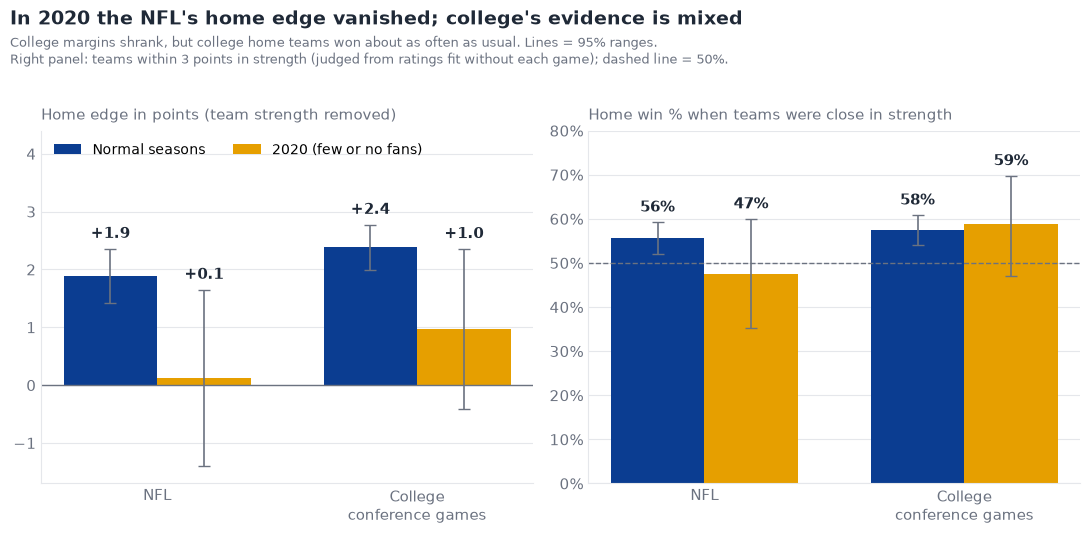

In [23]:
# Chart 8: 2020 vs. normal seasons, two ways: points (team strength removed) and real close matchups
order = ["NFL", "College (conference)"]
labels = ["NFL", "College\nconference games"]
x = range(len(order)); w = 0.36
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
panels = [
    (axes[0], "Home edge in points (team strength removed)", lambda per: A.xs(per, level="period").loc[order].rename(columns={"home_edge_pts": "v"}), "{:+.1f}", (-1.7, 4.4), 0),
    (axes[1], "Home win % when teams were close in strength", lambda per: close_games.xs(per, level=1).loc[order].rename(columns={"home_win_pct": "v"}), "{:.0f}%", (0, 80), 50),
]
for ax, sub, get, fmt, ylim, base in panels:
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for off, per, color, name in [(-w / 2, "normal", BLUE, "Normal seasons"), (w / 2, "2020", ORANGE, "2020 (few or no fans)")]:
        r = get(per); xs = [i + off for i in x]
        ax.bar(xs, r.v, w, color=color, label=name)
        ax.errorbar(xs, r.v, yerr=[r.v - r.low_95, r.high_95 - r.v], fmt="none", ecolor=MUTED, capsize=4, lw=1.2)
        for xi, v, hi in zip(xs, r.v, r.high_95):
            ax.text(xi, hi + (ylim[1] - ylim[0]) * 0.02, fmt.format(v), ha="center", va="bottom", color=INK, fontsize=11, fontweight="bold")
    ax.axhline(base, color=MUTED, lw=1, ls="--" if base else "-")
    ax.set_xticks(list(x), labels); ax.set_ylim(*ylim)
    ax.set_title(sub, loc="left", fontsize=11, color=MUTED, pad=8)
    tidy(ax)
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
axes[0].legend(frameon=False, loc="upper left", ncol=2, fontsize=10)
fig.suptitle("In 2020 the NFL's home edge vanished; college's evidence is mixed", x=0.012, y=0.985, ha="left", fontsize=14, fontweight="bold", color=INK)
fig.text(0.012, 0.885, "College margins shrank, but college home teams won about as often as usual. Lines = 95% ranges.\nRight panel: teams within 3 points in strength (judged from ratings fit without each game); dashed line = 50%.",
         color=MUTED, fontsize=9.5)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.savefig("charts/08_league_fan_effect.png", dpi=200); plt.show()

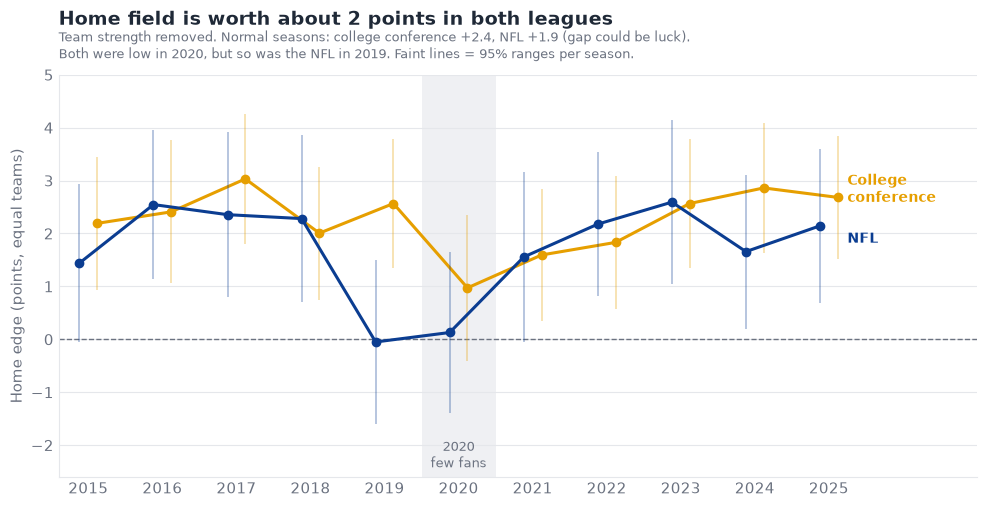

In [24]:
# Chart 9: strength-adjusted home edge by season, NFL vs. college conference games, 2020 shaded
s = season_edges.pivot(index="season", columns="group", values="home_edge")
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, lw=0)
ax.text(2020, -2.5, "2020\nfew fans", ha="center", va="bottom", color=MUTED, fontsize=9)
ax.axhline(0, ls="--", color=MUTED, lw=1)
se = season_edges.pivot(index="season", columns="group", values="se")
for name, color, nudge in [("College (conference)", ORANGE, 0.12), ("NFL", BLUE, -0.12)]:
    ax.errorbar(s.index + nudge, s[name], yerr=1.96 * se[name], fmt="none", ecolor=color, alpha=0.35, lw=1.2)
    ax.plot(s.index + nudge, s[name], color=color, lw=2.2, marker="o", ms=6)
ax.text(2025.25, s.loc[2025, "College (conference)"] + 0.15, "College\nconference", color=ORANGE, va="center", fontsize=10, fontweight="bold")
ax.text(2025.25, s.loc[2025, "NFL"] - 0.25, "NFL", color=BLUE, va="center", fontsize=10, fontweight="bold")
ax.set_xlim(2014.6, 2027.0); ax.set_ylim(-2.6, 5)
ax.set_xticks(range(2015, 2026)); ax.set_ylabel("Home edge (points, equal teams)")
n_avg = A.loc[("NFL", "normal"), "home_edge_pts"]; c_avg = A.loc[("College (conference)", "normal"), "home_edge_pts"]
ax.set_title("Home field is worth about 2 points in both leagues", loc="left", fontsize=14, fontweight="bold", pad=36)
ax.text(0, 1.03, f"Team strength removed. Normal seasons: college conference +{c_avg:.1f}, NFL +{n_avg:.1f} "
        f"(gap could be luck).\nBoth were low in 2020, but so was the NFL in 2019. Faint lines = 95% ranges per season.", transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")
tidy(ax); plt.tight_layout(); plt.savefig("charts/09_league_by_season.png", dpi=200); plt.show()

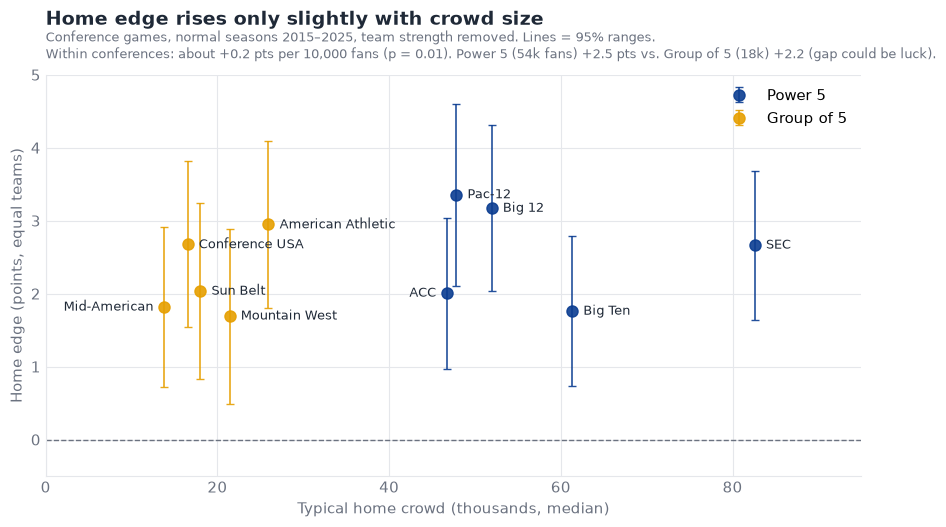

In [25]:
# Chart 10: home edge vs. typical crowd, by college conference (normal seasons, conference games)
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
c = confs.copy(); c["k"] = c.median_crowd / 1000
power = c.index.isin(POWER)
for mask, color, name in [(power, BLUE, "Power 5"), (~power, ORANGE, "Group of 5")]:
    ax.errorbar(c.k[mask], c.home_edge_pts[mask], yerr=1.96 * c.se[mask], fmt="o", color=color, ecolor=color, ms=8,
                elinewidth=1.2, alpha=0.9, capsize=3, label=name)
for conf, r in c.iterrows():
    left = conf in {"Mid-American", "ACC"}
    ax.annotate(conf, (r.k, r.home_edge_pts), xytext=(-8 if left else 8, 0), textcoords="offset points", va="center",
                ha="right" if left else "left", fontsize=9, color=INK)
ax.axhline(0, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, 95); ax.set_ylim(-0.5, 5)
ax.set_xlabel("Typical home crowd (thousands, median)"); ax.set_ylabel("Home edge (points, equal teams)")
ax.legend(frameon=False, loc="upper right")
t = tiers["home_edge_pts"]
ax.set_title("Home edge rises only slightly with crowd size", loc="left", fontsize=14, fontweight="bold", pad=36)
ax.text(0, 1.03, "Conference games, normal seasons 2015–2025, team strength removed. Lines = 95% ranges.\n"
        f"Within conferences: about +0.2 pts per 10,000 fans (p = 0.01). Power 5 ({tiers.median_crowd['Power 5'] / 1000:.0f}k fans) +{t['Power 5']:.1f} pts "
        f"vs. Group of 5 ({tiers.median_crowd['Group of 5'] / 1000:.0f}k) +{t['Group of 5']:.1f} (gap could be luck).",
        transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")
tidy(ax); plt.tight_layout(); plt.savefig("charts/10_crowd_size.png", dpi=200); plt.show()

## Findings
- **Home field is worth about 2 points in both leagues.** With team strength removed, normal seasons: college conference games **+2.4 pts** (95% range 2.0–2.8), NFL **+1.9 pts** (1.4–2.4). Between equally good teams, the home team wins about **57%** of the time in college and **56%** in the NFL. College is a little higher, but the gap could be luck (p = 0.11). This holds when blowouts are capped, when only wins are counted (college 57–60%, NFL 56%), and in real close matchups (57.5% vs. 55.6% home wins).
- **College only looks much bigger because of scheduling.** Across all FBS games home teams won **58.6%**, but in non-conference games the home team starts about **7 points stronger** (and wins 66.8%). With strength removed, non-conference games show the same +2.4-point edge as conference games.
- **In 2020 the NFL's home edge fell on every measure, but it's significant only in point margins:** +1.9 → **+0.1 pts** (p = 0.03); close matchups 55.6% → 47.5%; wins-only model p ≈ 0.16. And 2019, with full stadiums, was nearly as low, so this is the bottom of a two-year dip rather than a clean one-season effect.
- **College 2020 is mixed.** Margins shrank (+2.4 → +1.0 pts, p = 0.055), but home teams won about as often as usual (close matchups: 58.8% vs. 57.5%; wins-only model: no change at any setting, p ≈ 0.9), and the margin drop fades when blowouts are capped. So we can't say college home field shrank in 2020, and we can't say whether fans matter more in one league (p = 0.75).
- **Home edge rises only slightly with crowd size in college.** Within conferences, each extra 10,000 fans goes with about **+0.2 pts** (p = 0.01), though bigger crowds also mean bigger, more motivated games. Power 5 schools (median crowd 54,000) get **+2.5 pts** vs. **+2.2** for Group of 5 schools (18,000), a gap that could be luck. Crowd size clearly isn't the whole story: schools with modest crowds still get most of the edge.

**Limitations**
- 2020 is one season, and college teams played only 3–12 games, so 2020 estimates are noisy.
- "2020" means fewer fans, not zero: many college stadiums allowed partial crowds, and a few NFL stadiums did too. Recorded attendance of 0 may sometimes mean "not recorded".
- 2020 college schedules were mostly conference games, and some conferences played shortened seasons.
- Bigger crowds also come with bigger, more motivated games, so the crowd-size links are associations, not proof that fans cause anything.
- The usual-stadium rule leans on the API's venue labels, which are sometimes inconsistent, so a few genuine home games are dropped (21 games in total; negligible effect on results). Conference title games before 2022 are found by date, not by an official label.